# 01 · Exploratory data analysis — IBM Telco Customer Churn

Descriptive look at the demonstration data: structure, quality, target and associations with churn. Everything here is a **historical association in a sample data set** — not evidence of causes, and not a statement about any real company. The CSV is not redistributed: see `../data/README.md`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # run from the notebooks/ folder, no installation needed
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churnlens.config import load_config

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False})
config = load_config()

## 1. Load and standardise

`load_demo_dataset` refuses a missing file (the project never fabricates data) and a file that looks synthetic. `prepare_dataset` standardises text, converts numeric-looking text (`TotalCharges`) and validates the target.

In [2]:
from churnlens.data import load_demo_dataset, prepare_dataset

raw = load_demo_dataset(config)
prepared = prepare_dataset(raw, config.data.target, positive_label=config.data.positive_label,
                           id_column=config.data.id_column, config=config)
print(raw.shape, "->", prepared.frame.shape, "features;", len(prepared.y), "labelled rows")
for note in prepared.notes:
    print("-", note)
prepared.profile.columns

(7043, 21) -> (7043, 19) features; 7043 labelled rows
- 'TotalCharges' is numeric stored as text: converted to numbers (11 blank and 0 non-numeric value(s) became missing).


,column,dtype,missing,missing_%,unique,example
0,customerID,object,0,0.00,7043,7590-VHVEG
1,gender,object,0,0.00,2,Female
2,SeniorCitizen,int64,0,0.00,2,0
3,Partner,object,0,0.00,2,Yes
4,Dependents,object,0,0.00,2,No
5,tenure,int64,0,0.00,73,1
6,PhoneService,object,0,0.00,2,No
7,MultipleLines,object,0,0.00,3,No phone service
8,InternetService,object,0,0.00,3,DSL
9,OnlineSecurity,object,0,0.00,3,No


## 2. Data quality

In [3]:
p = prepared.profile
print(f"missing cells: {p.n_missing_cells} | rows identical apart from the id: {raw.drop(columns='customerID').duplicated().sum()} "
      f"| constant columns: {p.constant_columns}")
blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("blank TotalCharges:", int(blank.sum()), "| their tenure:", sorted(raw.loc[blank, "tenure"].unique()),
      "| their churn:", raw.loc[blank, "Churn"].unique().tolist())
tc = pd.to_numeric(raw["TotalCharges"], errors="coerce").fillna(0)
print("corr(TotalCharges, tenure x MonthlyCharges) =", round(float(np.corrcoef(tc, raw.tenure * raw.MonthlyCharges)[0, 1]), 4))

missing cells: 11 | rows identical apart from the id: 22 | constant columns: []
blank TotalCharges: 11 | their tenure: [np.int64(0)] | their churn: ['No']
corr(TotalCharges, tenure x MonthlyCharges) = 0.9996


The 11 blank `TotalCharges` are exactly the customers with `tenure = 0` (no bill yet): the pipeline sets them to 0 rather than imputing a median. `TotalCharges` is almost `tenure × MonthlyCharges`, so the three numeric columns are largely redundant.

## 3. Target

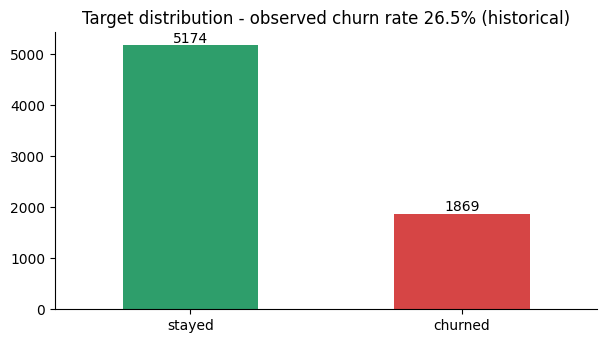

In [4]:
y = prepared.y
counts = y.value_counts().sort_index()
ax = counts.rename({0: "stayed", 1: "churned"}).plot.bar(color=["#2e9e6b", "#d64545"], rot=0)
ax.bar_label(ax.containers[0]); ax.set_title(f"Target distribution - observed churn rate {y.mean():.1%} (historical)")
plt.show()

## 4. Churn rate by category and by tenure

Observed historical rates, not predicted risks.

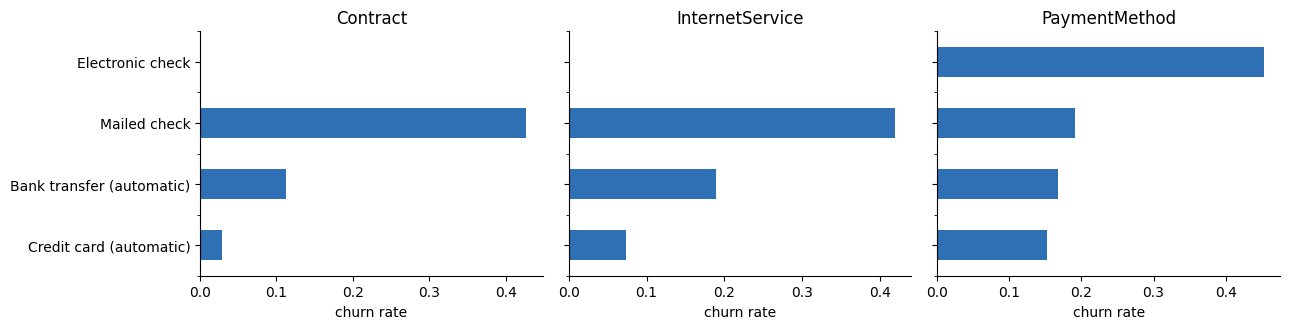

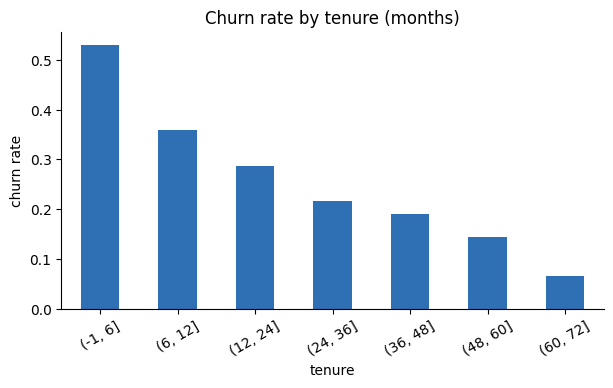

,mean,size
tenure,,
"(-1, 6]",0.529372,1481
"(6, 12]",0.358865,705
"(12, 24]",0.287109,1024
"(24, 36]",0.216346,832
"(36, 48]",0.190289,762
"(48, 60]",0.144231,832
"(60, 72]",0.066098,1407


In [5]:
df = prepared.frame.assign(churn=y)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["churn"].mean().sort_values()
    rate.plot.barh(ax=ax, color="#2f6fb3"); ax.set_title(col); ax.set_xlabel("churn rate"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

bins = pd.cut(df["tenure"], [-1, 6, 12, 24, 36, 48, 60, 72])
rate = df.groupby(bins, observed=True)["churn"].agg(["mean", "size"])
rate["mean"].plot.bar(color="#2f6fb3", rot=30); plt.title("Churn rate by tenure (months)"); plt.ylabel("churn rate"); plt.show()
rate

## 5. Numeric features by outcome

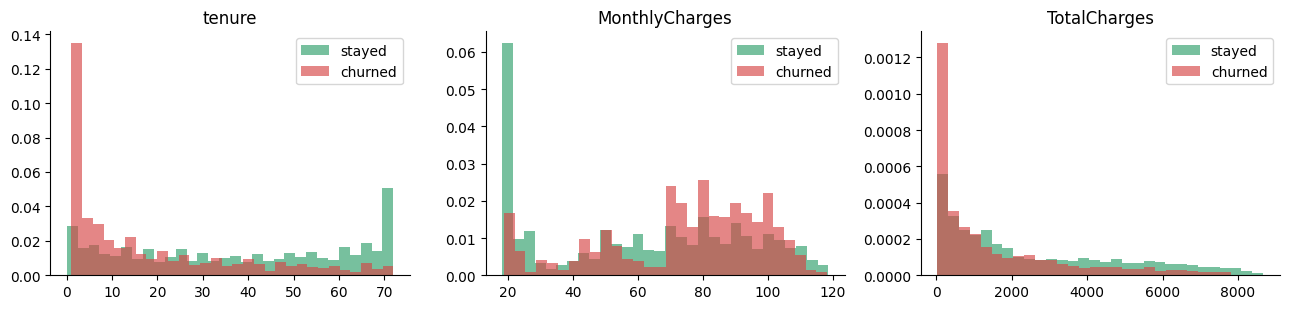

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    for value, name, color in ((0, "stayed", "#2e9e6b"), (1, "churned", "#d64545")):
        ax.hist(df.loc[df.churn == value, col], bins=30, alpha=0.65, color=color, label=name, density=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

## 6. Reading these results carefully

* Month-to-month contracts, fiber optic and electronic-check payers churn much more often **in this data** — associations that also correlate with each other (contract type, price, tenure).
* `tenure` and `TotalCharges` are cumulative values observed at extraction time; for churned customers they stop at departure, so part of their signal is a consequence of the outcome. The file has no dates, so this cannot be tested.
* `gender` and `SeniorCitizen` are present; no fairness analysis is done here.